In [1]:

import os
import platform
import pandas as pd
import time
import keras
from keras import layers
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

os.environ["KERAS_BACKEND"] = "tensorflow"

if platform.system() == "Darwin" and platform.machine() == "arm64":
    tf.config.set_visible_devices([], "GPU")

keras.utils.set_random_seed(0)
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

class_names = [
    "lentokone",
    "auto",
    "lintu",
    "kissa",
    "peura",
    "koira",
    "sammakko",
    "hevonen",
    "laiva",
    "kuorma-auto"
]

class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        self.start_time = time.perf_counter()

    def on_epoch_end(self, epoch, logs=None):
        elapsed = time.perf_counter() - self.start_time
        self.epoch_times.append(elapsed)

stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                     restore_best_weights=True)


 Baseline (4 kerrosta, 20 ep) 
Epoch 1/20
1407/1407 - 79s - 56ms/step - accuracy: 0.4933 - loss: 1.4060 - val_accuracy: 0.6350 - val_loss: 1.0507
Epoch 2/20
1407/1407 - 82s - 58ms/step - accuracy: 0.6645 - loss: 0.9576 - val_accuracy: 0.7084 - val_loss: 0.8552
Epoch 3/20
1407/1407 - 77s - 55ms/step - accuracy: 0.7246 - loss: 0.7914 - val_accuracy: 0.7174 - val_loss: 0.8240
Epoch 4/20
1407/1407 - 75s - 53ms/step - accuracy: 0.7625 - loss: 0.6904 - val_accuracy: 0.7274 - val_loss: 0.8137
Epoch 5/20
1407/1407 - 72s - 51ms/step - accuracy: 0.7913 - loss: 0.6065 - val_accuracy: 0.7294 - val_loss: 0.8432
Epoch 6/20
1407/1407 - 73s - 52ms/step - accuracy: 0.8158 - loss: 0.5382 - val_accuracy: 0.7226 - val_loss: 0.9313
Epoch 7/20
1407/1407 - 76s - 54ms/step - accuracy: 0.8326 - loss: 0.4853 - val_accuracy: 0.7218 - val_loss: 0.9993


Malli,Test accuracy,Test loss,Parametrit,Epookkeja,Paras epookki
Baseline,71.77%,0.8665,"106,538",7,4


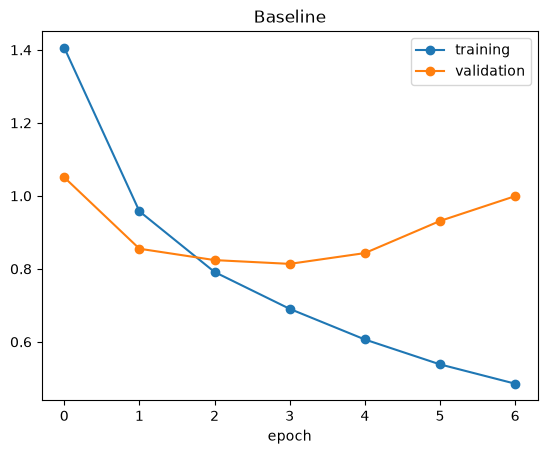

Train accuracy (viimeinen ep): 83.26%
Val accuracy (paras):          72.94%


In [2]:
print("\n Baseline (4 kerrosta, 20 ep) ")
keras.utils.set_random_seed(0)

model_baseline = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
    layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"),
    layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"),
    layers.MaxPooling2D(pool_size=2),
    layers.Flatten(),
    layers.Dense(10, activation="softmax")
])

model_baseline.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

timer_baseline = EpochTimer()
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

history_baseline = model_baseline.fit(
    x_train, y_train,
    epochs=20,
    validation_split=0.1,
    callbacks=[early_stop, timer_baseline],
    verbose=2
)

loss_baseline, acc_baseline = model_baseline.evaluate(x_test, y_test, verbose=0)
best_epoch_baseline = int(np.argmin(history_baseline.history["val_loss"])) + 1

df_baseline = pd.DataFrame([{
    "Malli": "Baseline",
    "Test accuracy": acc_baseline,
    "Test loss": loss_baseline,
    "Parametrit": model_baseline.count_params(),
    "Epookkeja": len(timer_baseline.epoch_times),
    "Paras epookki": best_epoch_baseline,
}])
display(df_baseline.style.hide(axis="index").format({"Test accuracy": "{:.2%}", "Test loss": "{:.4f}", "Parametrit": "{:,}"}))

plt.plot(history_baseline.history["loss"], marker="o", label="training")
plt.plot(history_baseline.history["val_loss"], marker="o", label="validation")
plt.xlabel("epoch")
plt.title("Baseline")
plt.legend()
plt.show()

print(f"Train accuracy (viimeinen ep): {history_baseline.history['accuracy'][-1]:.2%}")
print(f"Val accuracy (paras):          {max(history_baseline.history['val_accuracy']):.2%}")

## 5.1 Dropout
Lisätään verkkoon Dropout-kerros (0.3), joka sammuttaa satunnaisesti 30% neuroneista koulutuksen aikana. Tämän pitäisi estää verkkoa nojaamasta liikaa yksittäisiin neuroneihin ja vähentää ylisovittumista.


=== Dropout 0.2 ===
Epoch 1/20
1407/1407 - 77s - 55ms/step - accuracy: 0.4856 - loss: 1.4322 - val_accuracy: 0.6282 - val_loss: 1.0662
Epoch 2/20
1407/1407 - 75s - 53ms/step - accuracy: 0.6480 - loss: 1.0072 - val_accuracy: 0.6918 - val_loss: 0.9033
Epoch 3/20
1407/1407 - 82s - 58ms/step - accuracy: 0.7046 - loss: 0.8465 - val_accuracy: 0.7262 - val_loss: 0.8026
Epoch 4/20
1407/1407 - 78s - 55ms/step - accuracy: 0.7433 - loss: 0.7419 - val_accuracy: 0.7226 - val_loss: 0.8214
Epoch 5/20
1407/1407 - 77s - 54ms/step - accuracy: 0.7662 - loss: 0.6719 - val_accuracy: 0.7498 - val_loss: 0.7596
Epoch 6/20
1407/1407 - 78s - 55ms/step - accuracy: 0.7868 - loss: 0.6124 - val_accuracy: 0.7570 - val_loss: 0.7551
Epoch 7/20
1407/1407 - 76s - 54ms/step - accuracy: 0.8029 - loss: 0.5653 - val_accuracy: 0.7514 - val_loss: 0.7597
Epoch 8/20
1407/1407 - 78s - 55ms/step - accuracy: 0.8147 - loss: 0.5282 - val_accuracy: 0.7530 - val_loss: 0.7841
Epoch 9/20
1407/1407 - 79s - 56ms/step - accuracy: 0.8302 -

Malli,Test accuracy,Test loss,Parametrit,Epookkeja,Paras epookki
Dropout 0.2,73.13%,0.7919,"106,538",9,6


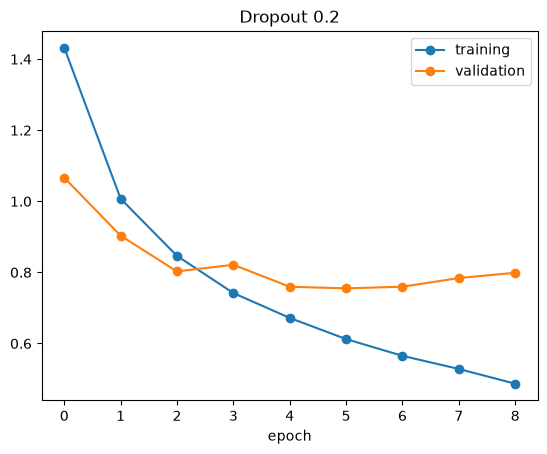

Train accuracy (viimeinen ep): 83.02%
Val accuracy (paras):          75.70%

=== Dropout 0.3 ===
Epoch 1/20
1407/1407 - 82s - 58ms/step - accuracy: 0.4904 - loss: 1.4248 - val_accuracy: 0.6378 - val_loss: 1.0448
Epoch 2/20
1407/1407 - 78s - 55ms/step - accuracy: 0.6476 - loss: 1.0016 - val_accuracy: 0.7036 - val_loss: 0.8683
Epoch 3/20
1407/1407 - 76s - 54ms/step - accuracy: 0.7015 - loss: 0.8518 - val_accuracy: 0.7306 - val_loss: 0.7994
Epoch 4/20
1407/1407 - 93s - 66ms/step - accuracy: 0.7346 - loss: 0.7627 - val_accuracy: 0.7350 - val_loss: 0.7831
Epoch 5/20
1407/1407 - 75s - 53ms/step - accuracy: 0.7544 - loss: 0.7013 - val_accuracy: 0.7366 - val_loss: 0.7811
Epoch 6/20
1407/1407 - 79s - 56ms/step - accuracy: 0.7742 - loss: 0.6486 - val_accuracy: 0.7434 - val_loss: 0.7673
Epoch 7/20
1407/1407 - 79s - 56ms/step - accuracy: 0.7877 - loss: 0.6060 - val_accuracy: 0.7486 - val_loss: 0.7629
Epoch 8/20
1407/1407 - 76s - 54ms/step - accuracy: 0.7996 - loss: 0.5686 - val_accuracy: 0.7556 - 

Malli,Test accuracy,Test loss,Parametrit,Epookkeja,Paras epookki
Dropout 0.3,75.22%,0.7730,"106,538",14,11


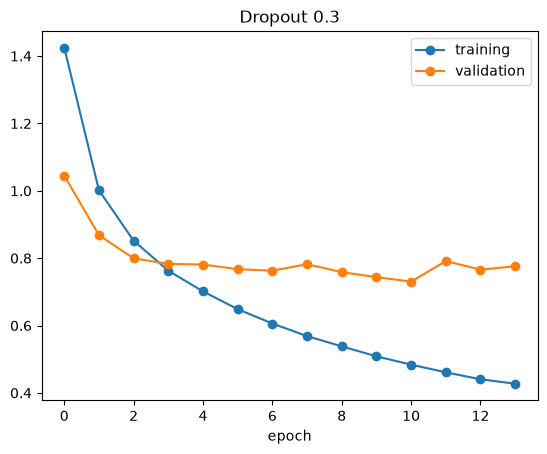

Train accuracy (viimeinen ep): 84.59%
Val accuracy (paras):          77.22%

=== Dropout 0.5 ===
Epoch 1/20
1407/1407 - 85s - 60ms/step - accuracy: 0.4511 - loss: 1.5138 - val_accuracy: 0.5888 - val_loss: 1.1598
Epoch 2/20
1407/1407 - 81s - 58ms/step - accuracy: 0.5978 - loss: 1.1354 - val_accuracy: 0.6700 - val_loss: 0.9573
Epoch 3/20
1407/1407 - 84s - 59ms/step - accuracy: 0.6544 - loss: 0.9848 - val_accuracy: 0.7028 - val_loss: 0.8590
Epoch 4/20
1407/1407 - 84s - 60ms/step - accuracy: 0.6852 - loss: 0.8932 - val_accuracy: 0.7310 - val_loss: 0.7929
Epoch 5/20
1407/1407 - 83s - 59ms/step - accuracy: 0.7083 - loss: 0.8294 - val_accuracy: 0.7410 - val_loss: 0.7553
Epoch 6/20
1407/1407 - 141s - 100ms/step - accuracy: 0.7273 - loss: 0.7765 - val_accuracy: 0.7458 - val_loss: 0.7557
Epoch 7/20
1407/1407 - 79s - 56ms/step - accuracy: 0.7396 - loss: 0.7390 - val_accuracy: 0.7492 - val_loss: 0.7562
Epoch 8/20
1407/1407 - 78s - 55ms/step - accuracy: 0.7512 - loss: 0.7043 - val_accuracy: 0.7566 

Malli,Test accuracy,Test loss,Parametrit,Epookkeja,Paras epookki
Dropout 0.5,76.56%,0.6960,"106,538",17,14


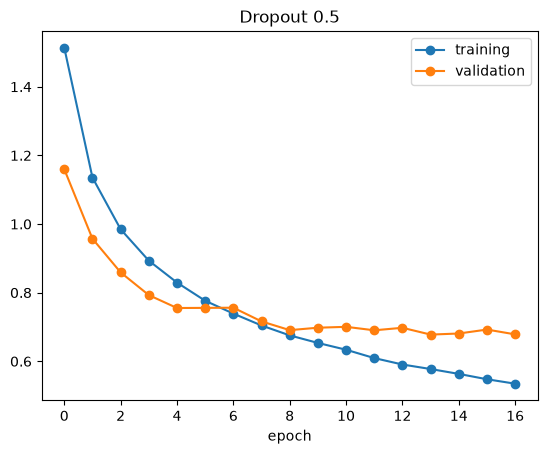

Train accuracy (viimeinen ep): 81.10%
Val accuracy (paras):          77.88%


In [3]:
def build_dropout(dropout_rate):
    model = keras.Sequential([
        keras.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
        layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"),
        layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Flatten(),
        layers.Dropout(dropout_rate),
        layers.Dense(10, activation="softmax")
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

for rate in [0.2, 0.3, 0.5]:
    print(f"\n=== Dropout {rate} ===")
    keras.utils.set_random_seed(0)
    
    model = build_dropout(rate)
    timer = EpochTimer()
    early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    
    history = model.fit(x_train, y_train, epochs=20, validation_split=0.1, callbacks=[early_stop, timer], verbose=2)
    
    loss, acc = model.evaluate(x_test, y_test, verbose=0)
    best_epoch = int(np.argmin(history.history["val_loss"])) + 1
    
    df = pd.DataFrame([{
        "Malli": f"Dropout {rate}",
        "Test accuracy": acc,
        "Test loss": loss,
        "Parametrit": model.count_params(),
        "Epookkeja": len(timer.epoch_times),
        "Paras epookki": best_epoch,
    }])
    display(df.style.hide(axis="index").format({"Test accuracy": "{:.2%}", "Test loss": "{:.4f}", "Parametrit": "{:,}"}))
    
    plt.plot(history.history["loss"], marker="o", label="training")
    plt.plot(history.history["val_loss"], marker="o", label="validation")
    plt.xlabel("epoch")
    plt.title(f"Dropout {rate}")
    plt.legend()
    plt.show()
    
    print(f"Train accuracy (viimeinen ep): {history.history['accuracy'][-1]:.2%}")
    print(f"Val accuracy (paras):          {max(history.history['val_accuracy']):.2%}")

#### Johtopäätökset: Dropout

Dropout-sweepin paras tulos saatiin arvolla **0.5**. Sen test accuracy oli **76.56 %**, test loss **0.6960** ja paras epookki **14**.

## 5.2 Data augmentation
Kokeillaan datan monipuolistamista kääntämällä kuvia vaakasuunnassa (RandomFlip) ja siirtämällä niitä hieman (RandomTranslation). Tämä pakottaa mallin oppimaan yleispätevämpiä piirteitä sen sijaan, että se opettelisi harjoituskuvat ulkoa.


=== RandomTranslation 0.05 ===
Epoch 1/20
1407/1407 - 100s - 71ms/step - accuracy: 0.4692 - loss: 1.4743 - val_accuracy: 0.5976 - val_loss: 1.1454
Epoch 2/20
1407/1407 - 96s - 68ms/step - accuracy: 0.6229 - loss: 1.0673 - val_accuracy: 0.6498 - val_loss: 1.0149
Epoch 3/20
1407/1407 - 96s - 68ms/step - accuracy: 0.6764 - loss: 0.9280 - val_accuracy: 0.6990 - val_loss: 0.8924
Epoch 4/20
1407/1407 - 96s - 68ms/step - accuracy: 0.7069 - loss: 0.8436 - val_accuracy: 0.7218 - val_loss: 0.8327
Epoch 5/20
1407/1407 - 96s - 68ms/step - accuracy: 0.7280 - loss: 0.7865 - val_accuracy: 0.7208 - val_loss: 0.8272
Epoch 6/20
1407/1407 - 96s - 69ms/step - accuracy: 0.7418 - loss: 0.7433 - val_accuracy: 0.7378 - val_loss: 0.7638
Epoch 7/20
1407/1407 - 97s - 69ms/step - accuracy: 0.7535 - loss: 0.7109 - val_accuracy: 0.7416 - val_loss: 0.7741
Epoch 8/20
1407/1407 - 96s - 68ms/step - accuracy: 0.7615 - loss: 0.6891 - val_accuracy: 0.7496 - val_loss: 0.7668
Epoch 9/20
1407/1407 - 96s - 68ms/step - accura

Malli,Test accuracy,Test loss,Parametrit,Epookkeja,Paras epookki
Aug 0.05,72.92%,0.7900,"106,538",9,6


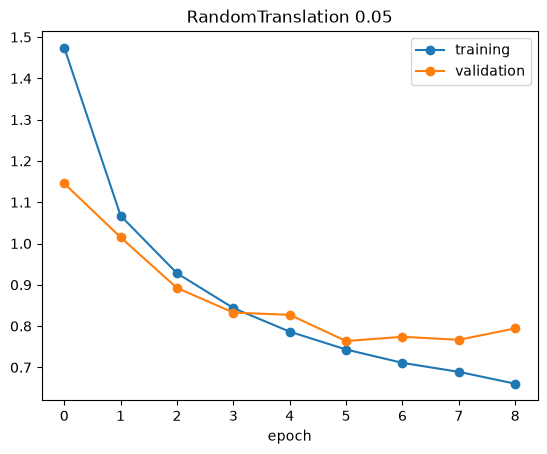

Train accuracy (viimeinen ep): 77.23%
Val accuracy (paras):          74.96%

=== RandomTranslation 0.1 ===
Epoch 1/20
1407/1407 - 100s - 71ms/step - accuracy: 0.4422 - loss: 1.5415 - val_accuracy: 0.5998 - val_loss: 1.1306
Epoch 2/20
1407/1407 - 97s - 69ms/step - accuracy: 0.5972 - loss: 1.1379 - val_accuracy: 0.6722 - val_loss: 0.9411
Epoch 3/20
1407/1407 - 97s - 69ms/step - accuracy: 0.6511 - loss: 0.9946 - val_accuracy: 0.7054 - val_loss: 0.8656
Epoch 4/20
1407/1407 - 96s - 68ms/step - accuracy: 0.6822 - loss: 0.9122 - val_accuracy: 0.7224 - val_loss: 0.8247
Epoch 5/20
1407/1407 - 141s - 100ms/step - accuracy: 0.7048 - loss: 0.8541 - val_accuracy: 0.7376 - val_loss: 0.7809
Epoch 6/20
1407/1407 - 97s - 69ms/step - accuracy: 0.7202 - loss: 0.8066 - val_accuracy: 0.7540 - val_loss: 0.7344
Epoch 7/20
1407/1407 - 96s - 68ms/step - accuracy: 0.7305 - loss: 0.7739 - val_accuracy: 0.7640 - val_loss: 0.7064
Epoch 8/20
1407/1407 - 97s - 69ms/step - accuracy: 0.7432 - loss: 0.7427 - val_accura

Malli,Test accuracy,Test loss,Parametrit,Epookkeja,Paras epookki
Aug 0.1,78.98%,0.6377,"106,538",20,20


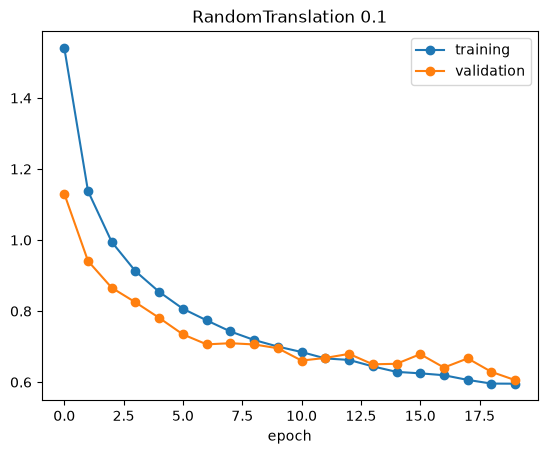

Train accuracy (viimeinen ep): 79.38%
Val accuracy (paras):          79.88%

=== RandomTranslation 0.2 ===
Epoch 1/20
1407/1407 - 101s - 72ms/step - accuracy: 0.3887 - loss: 1.6664 - val_accuracy: 0.5434 - val_loss: 1.2560
Epoch 2/20
1407/1407 - 96s - 69ms/step - accuracy: 0.5206 - loss: 1.3304 - val_accuracy: 0.6202 - val_loss: 1.0974
Epoch 3/20
1407/1407 - 97s - 69ms/step - accuracy: 0.5802 - loss: 1.1867 - val_accuracy: 0.6408 - val_loss: 1.0165
Epoch 4/20
1407/1407 - 97s - 69ms/step - accuracy: 0.6155 - loss: 1.0937 - val_accuracy: 0.6722 - val_loss: 0.9539
Epoch 5/20
1407/1407 - 97s - 69ms/step - accuracy: 0.6400 - loss: 1.0279 - val_accuracy: 0.7058 - val_loss: 0.8755
Epoch 6/20
1407/1407 - 166s - 118ms/step - accuracy: 0.6586 - loss: 0.9741 - val_accuracy: 0.7200 - val_loss: 0.8351
Epoch 7/20
1407/1407 - 100s - 71ms/step - accuracy: 0.6722 - loss: 0.9367 - val_accuracy: 0.7270 - val_loss: 0.7953
Epoch 8/20
1407/1407 - 99s - 70ms/step - accuracy: 0.6878 - loss: 0.9029 - val_accur

Malli,Test accuracy,Test loss,Parametrit,Epookkeja,Paras epookki
Aug 0.2,73.28%,0.7867,"106,538",11,8


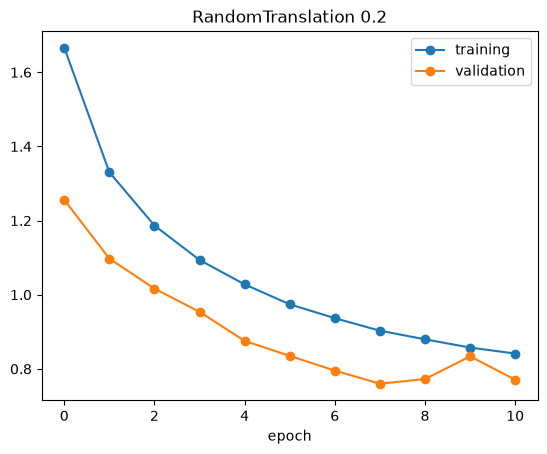

Train accuracy (viimeinen ep): 70.82%
Val accuracy (paras):          74.16%


In [4]:
def build_augmentation(translation):
    data_augmentation = keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomTranslation(translation, translation),
    ])

    model = keras.Sequential([
        keras.Input(shape=(32, 32, 3)),
        data_augmentation,
        layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
        layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"),
        layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Flatten(),
        layers.Dense(10, activation="softmax")
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

for t in [0.05, 0.1, 0.2]:
    print(f"\n=== RandomTranslation {t} ===")
    keras.utils.set_random_seed(0)
    
    model = build_augmentation(t)
    timer = EpochTimer()
    early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    
    history = model.fit(x_train, y_train, epochs=20, validation_split=0.1, callbacks=[early_stop, timer], verbose=2)
    
    loss, acc = model.evaluate(x_test, y_test, verbose=0)
    best_epoch = int(np.argmin(history.history["val_loss"])) + 1
    
    df = pd.DataFrame([{
        "Malli": f"Aug {t}",
        "Test accuracy": acc,
        "Test loss": loss,
        "Parametrit": model.count_params(),
        "Epookkeja": len(timer.epoch_times),
        "Paras epookki": best_epoch,
    }])
    display(df.style.hide(axis="index").format({"Test accuracy": "{:.2%}", "Test loss": "{:.4f}", "Parametrit": "{:,}"}))
    
    plt.plot(history.history["loss"], marker="o", label="training")
    plt.plot(history.history["val_loss"], marker="o", label="validation")
    plt.xlabel("epoch")
    plt.title(f"RandomTranslation {t}")
    plt.legend()
    plt.show()
    
    print(f"Train accuracy (viimeinen ep): {history.history['accuracy'][-1]:.2%}")
    print(f"Val accuracy (paras):          {max(history.history['val_accuracy']):.2%}")

### Augmentaatio (40 ep)

20 epookkia ei riittänyt konvergoitumiseen (paras epookki 20), joten ajetaan Aug 0.1.

In [6]:
print("\n=== RandomTranslation 0.1 (40 ep, patience=6) ===")
keras.utils.set_random_seed(0)

model_aug_40 = build_augmentation(0.1)
timer_aug_40 = EpochTimer()
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)

history_aug_40 = model_aug_40.fit(
    x_train, y_train, 
    epochs=40, 
    validation_split=0.1, 
    callbacks=[early_stop, timer_aug_40], 
    verbose=2
)

loss_aug_40, acc_aug_40 = model_aug_40.evaluate(x_test, y_test, verbose=0)
best_epoch_aug_40 = int(np.argmin(history_aug_40.history["val_loss"])) + 1

df_aug_40 = pd.DataFrame([{
    "Malli": "Aug 0.1 (40 ep)",
    "Test accuracy": acc_aug_40,
    "Test loss": loss_aug_40,
    "Parametrit": model_aug_40.count_params(),
    "Epookkeja": len(timer_aug_40.epoch_times),
    "Paras epookki": best_epoch_aug_40,
}])
display(df_aug_40.style.hide(axis="index").format({"Test accuracy": "{:.2%}", "Test loss": "{:.4f}", "Parametrit": "{:,}"}))


=== RandomTranslation 0.1 (40 ep, patience=6) ===
Epoch 1/40
1407/1407 - 103s - 73ms/step - accuracy: 0.4422 - loss: 1.5415 - val_accuracy: 0.5998 - val_loss: 1.1306
Epoch 2/40
1407/1407 - 100s - 71ms/step - accuracy: 0.5972 - loss: 1.1379 - val_accuracy: 0.6722 - val_loss: 0.9411
Epoch 3/40
1407/1407 - 98s - 69ms/step - accuracy: 0.6511 - loss: 0.9946 - val_accuracy: 0.7054 - val_loss: 0.8656
Epoch 4/40
1407/1407 - 98s - 70ms/step - accuracy: 0.6822 - loss: 0.9122 - val_accuracy: 0.7224 - val_loss: 0.8247
Epoch 5/40
1407/1407 - 100s - 71ms/step - accuracy: 0.7048 - loss: 0.8541 - val_accuracy: 0.7376 - val_loss: 0.7809
Epoch 6/40
1407/1407 - 99s - 70ms/step - accuracy: 0.7202 - loss: 0.8066 - val_accuracy: 0.7540 - val_loss: 0.7344
Epoch 7/40
1407/1407 - 139s - 99ms/step - accuracy: 0.7305 - loss: 0.7739 - val_accuracy: 0.7640 - val_loss: 0.7064
Epoch 8/40
1407/1407 - 99s - 70ms/step - accuracy: 0.7432 - loss: 0.7427 - val_accuracy: 0.7676 - val_loss: 0.7096
Epoch 9/40
1407/1407 - 98

Malli,Test accuracy,Test loss,Parametrit,Epookkeja,Paras epookki
Aug 0.1 (40 ep),78.98%,0.6377,"106,538",26,20


#### Johtopäätökset: Data Augmentaatio

Augmentaatio-sweepin paras tulos saatiin translation-arvolla **0.1**. Sen test accuracy oli **78.98 %**, test loss **0.6377**

## 5.3 Batch Normalization
Lisätään BatchNormalization-kerrokset konvoluutiokerrosten jälkeen. Tämä normalisoi kerrosten väliset syötteet, mikä vakauttaa ja nopeuttaa oppimista. 


 BatchNorm momentum 0.9 
Epoch 1/20
1407/1407 - 147s - 104ms/step - accuracy: 0.5358 - loss: 1.3342 - val_accuracy: 0.6640 - val_loss: 0.9921
Epoch 2/20
1407/1407 - 140s - 99ms/step - accuracy: 0.6937 - loss: 0.8808 - val_accuracy: 0.7234 - val_loss: 0.8096
Epoch 3/20
1407/1407 - 141s - 100ms/step - accuracy: 0.7479 - loss: 0.7224 - val_accuracy: 0.7410 - val_loss: 0.7537
Epoch 4/20
1407/1407 - 128s - 91ms/step - accuracy: 0.7870 - loss: 0.6140 - val_accuracy: 0.7430 - val_loss: 0.7668
Epoch 5/20
1407/1407 - 132s - 94ms/step - accuracy: 0.8180 - loss: 0.5252 - val_accuracy: 0.7618 - val_loss: 0.7266
Epoch 6/20
1407/1407 - 135s - 96ms/step - accuracy: 0.8479 - loss: 0.4452 - val_accuracy: 0.7648 - val_loss: 0.7575
Epoch 7/20
1407/1407 - 145s - 103ms/step - accuracy: 0.8743 - loss: 0.3762 - val_accuracy: 0.7576 - val_loss: 0.8139
Epoch 8/20
1407/1407 - 143s - 102ms/step - accuracy: 0.8966 - loss: 0.3148 - val_accuracy: 0.7566 - val_loss: 0.8421


Malli,Test accuracy,Test loss,Parametrit,Epookkeja,Paras epookki
BN 0.9,74.60%,0.7722,"107,306",8,5


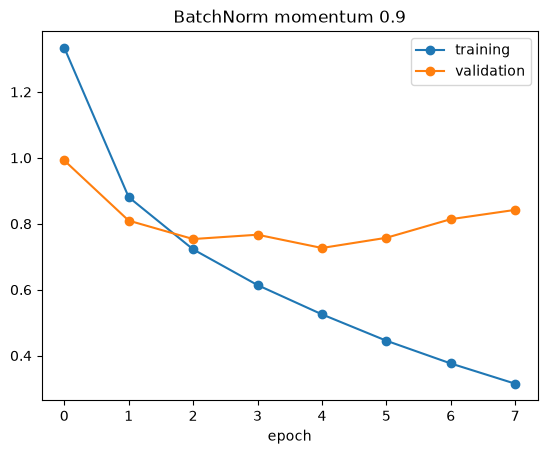

Train accuracy (viimeinen ep): 89.66%
Val accuracy (paras):          76.48%

 BatchNorm momentum 0.99 
Epoch 1/20
1407/1407 - 143s - 101ms/step - accuracy: 0.5358 - loss: 1.3342 - val_accuracy: 0.6268 - val_loss: 1.1088
Epoch 2/20
1407/1407 - 133s - 95ms/step - accuracy: 0.6937 - loss: 0.8808 - val_accuracy: 0.6646 - val_loss: 1.0285
Epoch 3/20
1407/1407 - 131s - 93ms/step - accuracy: 0.7479 - loss: 0.7224 - val_accuracy: 0.7036 - val_loss: 0.8945
Epoch 4/20
1407/1407 - 135s - 96ms/step - accuracy: 0.7870 - loss: 0.6140 - val_accuracy: 0.7284 - val_loss: 0.8150
Epoch 5/20
1407/1407 - 131s - 93ms/step - accuracy: 0.8180 - loss: 0.5252 - val_accuracy: 0.7372 - val_loss: 0.8141
Epoch 6/20
1407/1407 - 138s - 98ms/step - accuracy: 0.8479 - loss: 0.4452 - val_accuracy: 0.7202 - val_loss: 0.9262
Epoch 7/20
1407/1407 - 138s - 98ms/step - accuracy: 0.8743 - loss: 0.3762 - val_accuracy: 0.7260 - val_loss: 0.9280
Epoch 8/20
1407/1407 - 143s - 101ms/step - accuracy: 0.8966 - loss: 0.3148 - val_acc

Malli,Test accuracy,Test loss,Parametrit,Epookkeja,Paras epookki
BN 0.99,72.10%,0.8630,"107,306",8,5


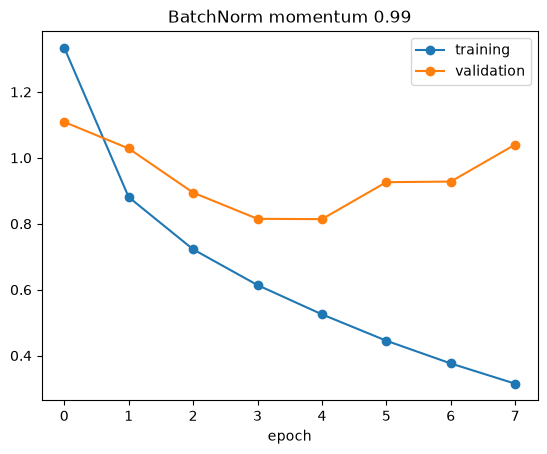

Train accuracy (viimeinen ep): 89.66%
Val accuracy (paras):          73.72%

 BatchNorm momentum 0.999 
Epoch 1/20
1407/1407 - 149s - 106ms/step - accuracy: 0.5358 - loss: 1.3342 - val_accuracy: 0.1170 - val_loss: 2.5798
Epoch 2/20
1407/1407 - 145s - 103ms/step - accuracy: 0.6937 - loss: 0.8808 - val_accuracy: 0.4624 - val_loss: 1.5224
Epoch 3/20
1407/1407 - 147s - 104ms/step - accuracy: 0.7479 - loss: 0.7224 - val_accuracy: 0.6630 - val_loss: 0.9803
Epoch 4/20
1407/1407 - 147s - 104ms/step - accuracy: 0.7870 - loss: 0.6140 - val_accuracy: 0.6808 - val_loss: 0.9579
Epoch 5/20
1407/1407 - 122s - 87ms/step - accuracy: 0.8180 - loss: 0.5252 - val_accuracy: 0.7248 - val_loss: 0.8568
Epoch 6/20
1407/1407 - 140s - 100ms/step - accuracy: 0.8479 - loss: 0.4452 - val_accuracy: 0.7134 - val_loss: 0.9591
Epoch 7/20
1407/1407 - 127s - 90ms/step - accuracy: 0.8743 - loss: 0.3762 - val_accuracy: 0.6904 - val_loss: 1.0681
Epoch 8/20
1407/1407 - 134s - 96ms/step - accuracy: 0.8966 - loss: 0.3148 - val

Malli,Test accuracy,Test loss,Parametrit,Epookkeja,Paras epookki
BN 0.999,71.36%,0.9018,"107,306",8,5


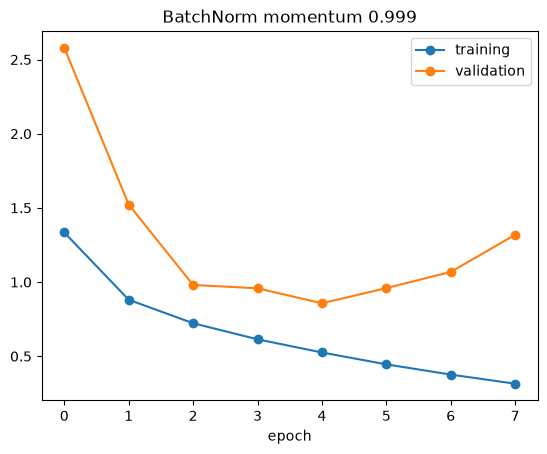

Train accuracy (viimeinen ep): 89.66%
Val accuracy (paras):          72.48%


In [5]:
def build_batchnorm(momentum):
    model = keras.Sequential([
        keras.Input(shape=(32, 32, 3)),
        layers.Conv2D(32, kernel_size=3, padding="same"),
        layers.BatchNormalization(momentum=momentum),
        layers.Activation("relu"),
        layers.Conv2D(32, kernel_size=3, padding="same"),
        layers.BatchNormalization(momentum=momentum),
        layers.Activation("relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Conv2D(64, kernel_size=3, padding="same"),
        layers.BatchNormalization(momentum=momentum),
        layers.Activation("relu"),
        layers.Conv2D(64, kernel_size=3, padding="same"),
        layers.BatchNormalization(momentum=momentum),
        layers.Activation("relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Flatten(),
        layers.Dense(10, activation="softmax")
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

for mom in [0.9, 0.99, 0.999]:
    print(f"\n BatchNorm momentum {mom} ")
    keras.utils.set_random_seed(0)
    
    model = build_batchnorm(mom)
    timer = EpochTimer()
    early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    
    history = model.fit(x_train, y_train, epochs=20, validation_split=0.1, callbacks=[early_stop, timer], verbose=2)
    
    loss, acc = model.evaluate(x_test, y_test, verbose=0)
    best_epoch = int(np.argmin(history.history["val_loss"])) + 1
    
    df = pd.DataFrame([{
        "Malli": f"BN {mom}",
        "Test accuracy": acc,
        "Test loss": loss,
        "Parametrit": model.count_params(),
        "Epookkeja": len(timer.epoch_times),
        "Paras epookki": best_epoch,
    }])
    display(df.style.hide(axis="index").format({"Test accuracy": "{:.2%}", "Test loss": "{:.4f}", "Parametrit": "{:,}"}))
    
    plt.plot(history.history["loss"], marker="o", label="training")
    plt.plot(history.history["val_loss"], marker="o", label="validation")
    plt.xlabel("epoch")
    plt.title(f"BatchNorm momentum {mom}")
    plt.legend()
    plt.show()
    
    print(f"Train accuracy (viimeinen ep): {history.history['accuracy'][-1]:.2%}")
    print(f"Val accuracy (paras):          {max(history.history['val_accuracy']):.2%}")

#### Johtopäätökset: BatchNorm

BatchNorm-sweepin paras tulos saatiin momentum-arvolla **0.9**. Sen test accuracy oli **74.60 %**, test loss **0.7722** ja paras epookki **5**.

### 5.4 Täysin regularisoitu malli (BN + Dropout + Augmentaatio)

Yhdistetään kaikki kolme regularisointitekniikkaa: BatchNorm (momentum 0.9), Dropout (0.5) ja Data Augmentation (0.1). Tavoitteena on saada aikaan malli, joka ei ylisovita ja saavuttaa parhaan testitarkkuuden.


 Täysin regularisoitu malli: BN 0.9 + Dropout 0.5 + Aug 0.1 (40 ep, patience=6) 
Epoch 1/40
1407/1407 - 168s - 120ms/step - accuracy: 0.4269 - loss: 1.6496 - val_accuracy: 0.5196 - val_loss: 1.3631
Epoch 2/40
1407/1407 - 164s - 117ms/step - accuracy: 0.5856 - loss: 1.1710 - val_accuracy: 0.6662 - val_loss: 0.9819
Epoch 3/40
1407/1407 - 162s - 115ms/step - accuracy: 0.6477 - loss: 1.0076 - val_accuracy: 0.7024 - val_loss: 0.8734
Epoch 4/40
1407/1407 - 165s - 117ms/step - accuracy: 0.6813 - loss: 0.9209 - val_accuracy: 0.6922 - val_loss: 0.9284
Epoch 5/40
1407/1407 - 165s - 117ms/step - accuracy: 0.6991 - loss: 0.8595 - val_accuracy: 0.7458 - val_loss: 0.7519
Epoch 6/40
1407/1407 - 163s - 116ms/step - accuracy: 0.7165 - loss: 0.8106 - val_accuracy: 0.7562 - val_loss: 0.7141
Epoch 7/40
1407/1407 - 165s - 117ms/step - accuracy: 0.7286 - loss: 0.7789 - val_accuracy: 0.7704 - val_loss: 0.6644
Epoch 8/40
1407/1407 - 164s - 117ms/step - accuracy: 0.7375 - loss: 0.7539 - val_accuracy: 0.7668 -

Malli,Test accuracy,Test loss,Parametrit,Epookkeja,Paras epookki
Täysin regularisoitu (BN 0.9 + Dropout 0.5 + Aug 0.1),83.00%,0.5136,"107,306",38,32


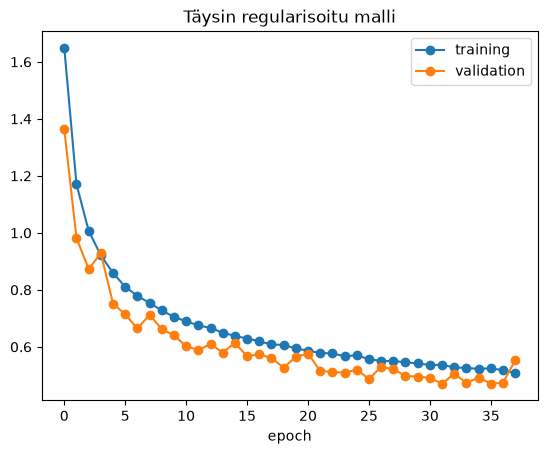

Train accuracy (viimeinen ep): 82.27%
Val accuracy (paras):          84.84%


In [7]:
def build_regularized_model(dropout_rate=0.5, translation=0.1, momentum=0.9):
    data_augmentation = keras.Sequential([
        layers.RandomFlip("horizontal"),
        layers.RandomTranslation(translation, translation),
    ])

    model = keras.Sequential([
        keras.Input(shape=(32, 32, 3)),
        data_augmentation,

        layers.Conv2D(32, kernel_size=3, padding="same"),
        layers.BatchNormalization(momentum=momentum),
        layers.Activation("relu"),
        layers.Conv2D(32, kernel_size=3, padding="same"),
        layers.BatchNormalization(momentum=momentum),
        layers.Activation("relu"),
        layers.MaxPooling2D(pool_size=2),

        layers.Conv2D(64, kernel_size=3, padding="same"),
        layers.BatchNormalization(momentum=momentum),
        layers.Activation("relu"),
        layers.Conv2D(64, kernel_size=3, padding="same"),
        layers.BatchNormalization(momentum=momentum),
        layers.Activation("relu"),
        layers.MaxPooling2D(pool_size=2),

        layers.Flatten(),
        layers.Dropout(dropout_rate),
        layers.Dense(10, activation="softmax")
    ])
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model


print("\n Täysin regularisoitu malli: BN 0.9 + Dropout 0.5 + Aug 0.1 (40 ep, patience=6) ")
keras.utils.set_random_seed(0)

model_regularized = build_regularized_model(dropout_rate=0.5, translation=0.1, momentum=0.9)
timer_regularized = EpochTimer()
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=6, restore_best_weights=True
)

history_regularized = model_regularized.fit(
    x_train, y_train,
    epochs=40,
    validation_split=0.1,
    callbacks=[early_stop, timer_regularized],
    verbose=2
)

loss_reg, acc_reg = model_regularized.evaluate(x_test, y_test, verbose=0)
best_epoch_reg = int(np.argmin(history_regularized.history["val_loss"])) + 1

df_regularized = pd.DataFrame([{
    "Malli": "Täysin regularisoitu (BN 0.9 + Dropout 0.5 + Aug 0.1)",
    "Test accuracy": acc_reg,
    "Test loss": loss_reg,
    "Parametrit": model_regularized.count_params(),
    "Epookkeja": len(timer_regularized.epoch_times),
    "Paras epookki": best_epoch_reg,
}])
display(df_regularized.style.hide(axis="index").format({
    "Test accuracy": "{:.2%}",
    "Test loss": "{:.4f}",
    "Parametrit": "{:,}",
}))

plt.plot(history_regularized.history["loss"], marker="o", label="training")
plt.plot(history_regularized.history["val_loss"], marker="o", label="validation")
plt.xlabel("epoch")
plt.title("Täysin regularisoitu malli")
plt.legend()
plt.show()

print(f"Train accuracy (viimeinen ep): {history_regularized.history['accuracy'][-1]:.2%}")
print(f"Val accuracy (paras):          {max(history_regularized.history['val_accuracy']):.2%}")

### Regularisoidun mallin tulokset

Yhdistelmämalli saavutti **83.00 % test accuracyn** (loss 0.5136). Paras epoch 
oli **32** ja koulutus kesti 38 epookkia – noin 10× baseline. Val accuracy 
(84.84 %) ylitti train accuracyn (82.27 %), koska dropout ja augmentaatio 
vaikuttavat vain treenaukseen. Käytännössä ylisovittamista ei siis enää ole: 
baseline-mallin −10 pp train/val-ero on kääntynyt +2.57 pp:hen.

Huomionarvoista: **suurin osa hyödystä tuli jo Aug 0.1:stä yksin** (78.98 %). 
BN ja dropout toivat siihen päälle enää ~4 pp, mutta moninkertaistivat 
koulutusajan. Jos laskentaresurssit olisivat rajalliset, pelkkä augmentaatio 
olisi parempi valinta.

#### Väärin luokiteltujen kuvien tarkastelu

Kuvat havainnollistavat mallin virheellisiä luokitteluja. Tarkastelu paljastaa, mitkä luokat tuottavat mallille eniten haasteita ja miksi.

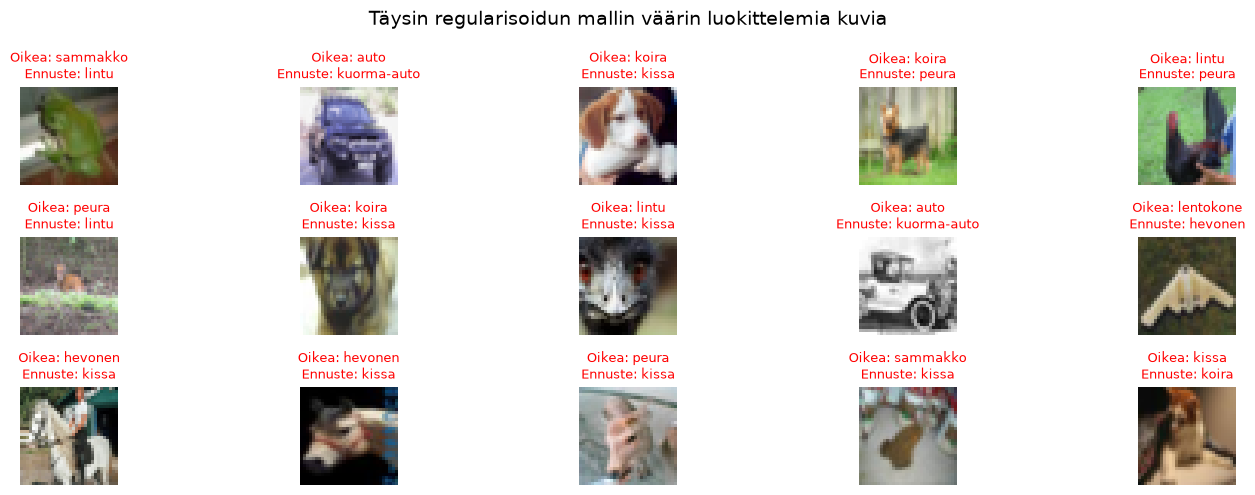

In [8]:
y_pred_reg = model_regularized.predict(x_test, verbose=0)
y_pred_classes_reg = np.argmax(y_pred_reg, axis=1)
y_true = y_test.flatten()

wrong_indices_reg = np.where(y_pred_classes_reg != y_true)[0]

plt.figure(figsize=(15, 5))
for i, idx in enumerate(wrong_indices_reg[:15]):
    plt.subplot(3, 5, i+1)
    plt.imshow(x_test[idx])
    plt.title(f"Oikea: {class_names[y_true[idx]]}\nEnnuste: {class_names[y_pred_classes_reg[idx]]}", fontsize=9, color="red")
    plt.axis("off")
plt.suptitle("Täysin regularisoidun mallin väärin luokittelemia kuvia", fontsize=14)
plt.tight_layout()
plt.show()

#### Accuracy learning curve

Accuracy learning curve kuvaa luokittelutarkkuuden kehitystä koulutuksen aikana. Harjoitus- ja validointikäyrien välinen etäisyys havainnollistaa mallin kykyä yleistää oppimansa uuteen dataan.

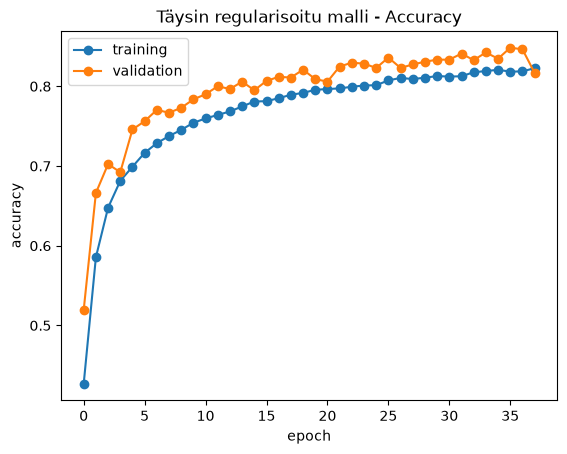

In [9]:
plt.plot(history_regularized.history["accuracy"], marker="o", label="training")
plt.plot(history_regularized.history["val_accuracy"], marker="o", label="validation")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.title("Täysin regularisoitu malli - Accuracy")
plt.legend()
plt.show()

#### Accuracy learning curve

Train- ja val-käyrät kulkevat lähes käsi kädessä koko koulutuksen ajan, eli 
malli ei ylisovita. Baseline-mallilla val-accuracy kääntyisi laskuun jo 
neljännen epookin jälkeen.

### Yhteenveto kaikista kokeista

**Järjestetty test accuracyn mukaan (paras ensin):**

| Malli | Test acc | Test loss | Δ baseline | Paras epoch | Epookkeja | Parametrit | Overfitting (train − val) |
|-------|----------|-----------|-----------|-------------|-----------|-----------|---------------------------|
| Täysin regularisoitu (BN 0.9 + Drop 0.5 + Aug 0.1) | 83.00 % | 0.5136 | +11.23 pp | 32 | 38 | 107,306 | −2.57 pp |
| Aug 0.1 | 78.98 % | 0.6377 | +7.21 pp | 20 | 20 | 106,538 | −0.50 pp |
| Dropout 0.5 | 76.56 % | 0.6960 | +4.79 pp | 14 | 17 | 106,538 | +3.22 pp |
| Dropout 0.3 | 75.22 % | 0.7730 | +3.45 pp | 11 | 14 | 106,538 | +7.37 pp |
| BN 0.9 | 74.60 % | 0.7722 | +2.83 pp | 5 | 8 | 107,306 | +13.18 pp |
| Aug 0.2 | 73.28 % | 0.7867 | +1.51 pp | 8 | 11 | 106,538 | −3.34 pp |
| Dropout 0.2 | 73.13 % | 0.7919 | +1.36 pp | 6 | 9 | 106,538 | +7.32 pp |
| Aug 0.05 | 72.92 % | 0.7900 | +1.15 pp | 6 | 9 | 106,538 | +2.27 pp |
| BN 0.99 | 72.10 % | 0.8630 | +0.33 pp | 5 | 8 | 107,306 | +15.94 pp |
| Baseline | 71.77 % | 0.8665 | – | 4 | 7 | 106,538 | +10.32 pp |
| BN 0.999 | 71.36 % | 0.9018 | −0.41 pp | 5 | 8 | 107,306 | +17.18 pp |
